<a href="https://colab.research.google.com/github/Pedro050723/Projeto-Pratico-2.1-Pedro-Miranda/blob/main/Projeto_Pr%C3%A1tico2_1_RNA_PEDRO_HENRIQUE_MIRANDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Redes Neurais Artificiais – Projeto Prático 2.1

**Aluno:** Pedro Henrique Miranda do Valle

## Parte I – Perceptron em um problema linearmente separável

**Objetivo:** implementar o algoritmo de treinamento do neurônio Perceptron (Rosenblatt) e usá-lo para separar duas classes de pontos do arquivo `dataAll20262.txt`.

##Importando as bibliotecas

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [7]:
Caminho = "dataAll20262.txt"

dados = np.load(Caminho)            # lê o ndarray salvo em binário
print("Shape original:", dados.shape)

dados = dados.reshape(-1, 3)        # (m, 1, 3) -> (m, 3)




print("Shape após reshape:", dados.shape)

print("\nPrimeiras 5 linhas (x1, x2, yd):")
print(dados[:5])

Shape original: (1000, 1, 3)
Shape após reshape: (1000, 3)

Primeiras 5 linhas (x1, x2, yd):
[[ 547.91209711 -122.2431205     1.        ]
 [ 717.19583982  394.73605812    0.        ]
 [-811.64530422  951.24470327    0.        ]
 [ 522.27940398  572.12861055    0.        ]
 [-743.77273465  -99.22812421    0.        ]]


In [8]:
X_orig = dados[:, :2]          # todas as linhas, colunas 0 e 1  -> (x1, x2)
y_d    = dados[:, 2]           # todas as linhas, coluna 2        -> rótulo

m = X_orig.shape[0]
print("Número de exemplos:", m)

classes, contagens = np.unique(y_d, return_counts=True)
for c, n in zip(classes, contagens):
    print(f"Classe {int(c)}: {n} exemplos")

Número de exemplos: 1000
Classe 0: 500 exemplos
Classe 1: 500 exemplos


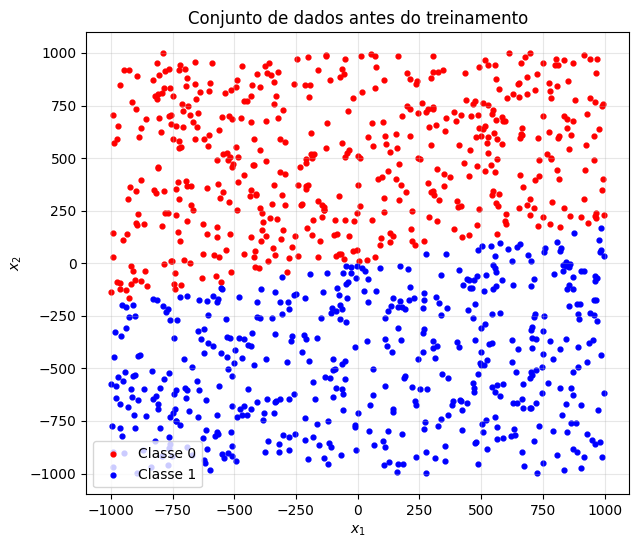

In [9]:
plt.figure(figsize=(7, 6))
plt.scatter(X_orig[y_d == 0, 0], X_orig[y_d == 0, 1], c="red",  s=12, label="Classe 0")
plt.scatter(X_orig[y_d == 1, 0], X_orig[y_d == 1, 1], c="blue", s=12, label="Classe 1")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$")
plt.title("Conjunto de dados antes do treinamento")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

##Preparação da entrada: coluna de *bias* (*viés*)

In [10]:
coluna_bias = np.ones((m, 1))                 # coluna de 1's, shape (m, 1)
X = np.hstack([coluna_bias, X_orig])          # junta lado a lado -> (m, 3)

print("Shape de X:", X.shape)
print("Primeiras 3 linhas de X  [1, x1, x2]:")
print(X[:3])

Shape de X: (1000, 3)
Primeiras 3 linhas de X  [1, x1, x2]:
[[   1.          547.91209711 -122.2431205 ]
 [   1.          717.19583982  394.73605812]
 [   1.         -811.64530422  951.24470327]]


## Hiperparâmetros e pesos iniciais

Exigências do enunciado:

- taxa de aprendizado $\eta = 0{,}1$;
- ativação degrau com limiar $\vartheta = 0$;
- pesos iniciais $w_i \sim U(-0{,}5, +0{,}5)$ (distribuição uniforme), **impressos no início**.


In [12]:
ETA = 0.1                 # taxa de aprendizado
Limiar = 0.0              # θ da função degrau
INTERVALO_PESOS = (-0.5, 0.5)
SEMENTE = None              # pode-se optar por um valor fixo para verificação da execução

if SEMENTE is not None:
    np.random.seed(SEMENTE)

# 3 pesos: w0 (bias), w1, w2 — sorteados uniformemente em [-0.5, 0.5)
w_inicial = np.random.uniform(INTERVALO_PESOS[0], INTERVALO_PESOS[1], size=3)

print("Vetor de pesos inicial [w0, w1, w2]:", w_inicial)

Vetor de pesos inicial [w0, w1, w2]: [-0.19964734  0.44228127 -0.11629671]


## A teoria

**Potencial de ativação:** $u = \mathbf{w}\cdot\mathbf{x}$

**Função de ativação degrau** (com $\vartheta = 0$):

$$y = \begin{cases} 1 & \text{se } u \ge 0 \\ 0 & \text{se } u < 0 \end{cases}$$

**Regra de aprendizado do Perceptron** — só altera os pesos quando **erra**:

$$\mathbf{w} \leftarrow \mathbf{w} + \eta\,(y_d - y)\,\mathbf{x}$$

Repare no que $(y_d - y)$ faz:

| $y_d$ | $y$ (obtido) | $y_d - y$ | efeito |
|:-:|:-:|:-:|---|
| 1 | 0 | **+1** | $\mathbf{w}$ se aproxima de $\mathbf{x}$ (aumenta $u$) |
| 0 | 1 | **−1** | $\mathbf{w}$ se afasta de $\mathbf{x}$ (diminui $u$) |
| igual | igual | 0 | nada muda |

**Vocabulário:**

- **Ajuste** = cada vez que o vetor de pesos é modificado (ou seja, cada erro corrigido).
- **Época** = uma passada completa por todos os exemplos de treinamento.
- **Convergência** = uma época inteira **sem nenhum erro**.

##Implementação do Treinamento

In [13]:
def degrau(u, limiar=0.0):
    # Retorna 1 se u >= limiar, senão 0
    return 1 if u >= limiar else 0

In [32]:
def treino_perceptron(X, y_d, eta, w_inicial, limiar=0.0, max_epocas=100000):
    w = w_inicial.copy()      # copia para não alterar o vetor original
    ajustes = 0               # total de vezes que w foi modificado
    epocas = 0                # épocas executadas
    convergiu = False

    while epocas < max_epocas:
        epocas += 1
        erros_na_epoca = 0

        for i in range(X.shape[0]):          # percorre todos os exemplos
            u = np.dot(w, X[i])              # potencial de ativação: w · x
            y = degrau(u, limiar)            # saída do neurônio

            if y != y_d[i]:                  # errou?
                w = w + eta * (y_d[i] - y) * X[i]   # (c) regra do Perceptron
                ajustes += 1
                erros_na_epoca += 1

        if erros_na_epoca == 0:              # época sem erros-> convergiu
            convergiu = True
            break

    return w, ajustes, epocas, convergiu

## Executando e imprimindo os resultados

O enunciado pede, ao final: **(a)** número total de ajustes no vetor de pesos e **(b)** número de épocas até a convergência. (O vetor inicial já foi impresso anteriormente)

> **Convenção de contagem:** a última época (a que passa sem erros) também é contada, pois é nela que comprovamos a convergência.

In [23]:
print("Vetor de pesos inicial :", w_inicial)

w_final, total_ajustes, total_epocas, convergiu = treino_perceptron(X, y_d, ETA, w_inicial, Limiar)

print("Vetor de pesos final   :", w_final)
print("\n(a) Número total de ajustes no vetor de pesos:", total_ajustes)
print("(b) Número de épocas até a convergência:", total_epocas)
print("(c) Vetor de pesos inicial:", w_inicial)

Vetor de pesos inicial : [-0.19964734  0.44228127 -0.11629671]
Vetor de pesos final   : [  -0.59964734   77.48321433 -386.28573861]

(a) Número total de ajustes no vetor de pesos: 42
(b) Número de épocas até a convergência: 3
(c) Vetor de pesos inicial: [-0.19964734  0.44228127 -0.11629671]


## O gráfico com os dados e a reta de separação

A fronteira de decisão é onde $u = 0$:

$$w_0 + w_1 x_1 + w_2 x_2 = 0 \;\;\Longrightarrow\;\; x_2 = -\frac{w_0 + w_1 x_1}{w_2}$$

Escolhemi dois valores de $x_1$ (as pontas do gráfico), calculei o $x_2$ correspondente e desenhei a reta entre eles. Como $x_2$ poderia sair do quadro, fixei os limites do eixo y com `plt.ylim`

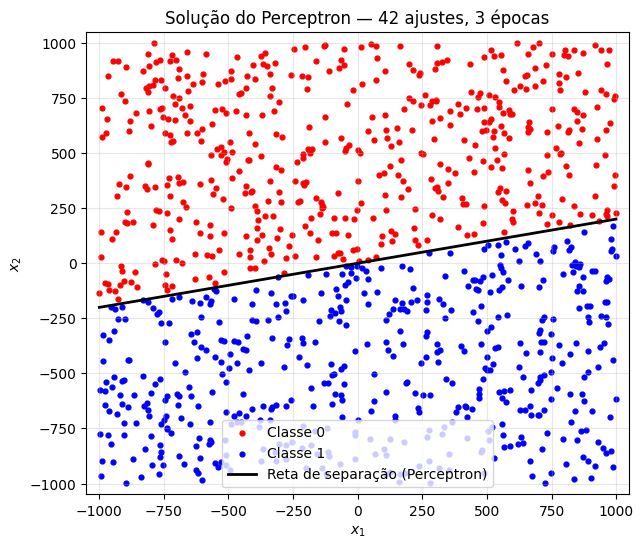

In [36]:
w0, w1, w2 = w_final

x1_reta = np.array([X_orig[:, 0].min(), X_orig[:, 0].max()])   # extremos do eixo x1
x2_reta = -(w0 + w1 * x1_reta) / w2                             # x2 correspondente

plt.figure(figsize=(7, 6))
plt.scatter(X_orig[y_d == 0, 0], X_orig[y_d == 0, 1], c="red",  s=12, label="Classe 0")
plt.scatter(X_orig[y_d == 1, 0], X_orig[y_d == 1, 1], c="blue", s=12, label="Classe 1")
plt.plot(x1_reta, x2_reta, "k-", linewidth=2, label="Reta de separação (Perceptron)")

plt.xlim(X_orig[:, 0].min() - 50, X_orig[:, 0].max() + 50)
plt.ylim(X_orig[:, 1].min() - 50, X_orig[:, 1].max() + 50)
plt.xlabel("$x_1$"); plt.ylabel("$x_2$")
plt.title(f"Solução do Perceptron — {total_ajustes} ajustes, {total_epocas} épocas")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

## Parte II – Experimentação

**Objetivo:** descobrir se a escolha da **taxa de aprendizado** ($\eta$) e do **intervalo dos pesos iniciais** ($I$) muda o desempenho do Perceptron.

O enunciado pede:

- usar o **arquivo da dupla** (`data020262.txt`);
- testar as **6 configurações** $\eta \times I = \{0{,}4;\ 0{,}1;\ 0{,}01\} \times \{(-100,+100);\ (-0{,}5,+0{,}5)\}$;
- rodar **10 repetições** de cada configuração (cada uma com pesos iniciais sorteados de novo);
- para cada configuração, registrar **média e desvio padrão do nº de ajustes**, **mínimo** e **máximo de épocas**;
- mostrar tudo numa **tabela** (`prettytable`), fazer um **boxplot** e **argumentar** se alguma configuração é melhor, pior ou se são equivalentes.

In [21]:
from prettytable import PrettyTable

## O ID e o arquivo de dados utilizado

Regra: **somar o último dígito das matrículas** dos integrantes e aplicar o **resto da divisão por 4** (`% 4`) ao resultado. O número obtido (0, 1, 2 ou 3) é o **ID**, e ele escolhe o arquivo: ID 3 → `data320262.txt`.

Fim da matrícula é 8, resto 0 logo o arquivo utilizado será `data020262.txt`.

In [34]:
CaminhoID = "data020262.txt"
ID = 0
print("Arquivo a ser usado:", CaminhoID)

Arquivo a ser usado: data020262.txt


In [27]:
dados_exp = np.load(CaminhoID).reshape(-1, 3)   # (m, 3): x1, x2, yd

X_orig_exp = dados_exp[:, :2]                        # entradas (x1, x2)
y_exp      = dados_exp[:, 2]                         # saídas desejadas (0 ou 1)
m_exp      = X_orig_exp.shape[0]

X_exp = np.hstack([np.ones((m_exp, 1)), X_orig_exp]) # adiciona a coluna de bias -> (m_exp, 3)

print("Exemplos:", m_exp, "| shape de X_exp:", X_exp.shape)
print("Classe 0:", int(np.sum(y_exp == 0)), "| Classe 1:", int(np.sum(y_exp == 1)))

Exemplos: 1000 | shape de X_exp: (1000, 3)
Classe 0: 566 | Classe 1: 434


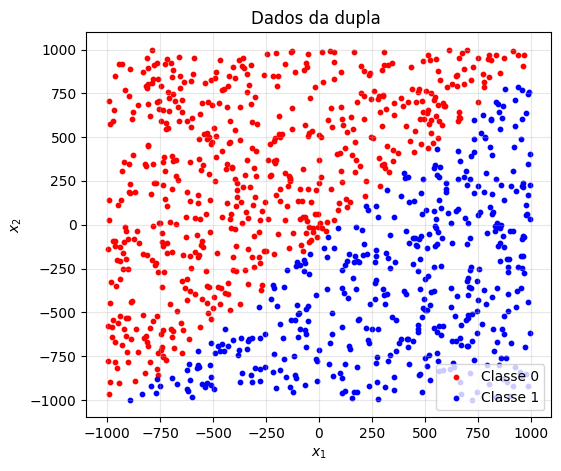

In [29]:
plt.figure(figsize=(6, 5))
plt.scatter(X_orig_exp[y_exp == 0, 0], X_orig_exp[y_exp == 0, 1], c="red",  s=10, label="Classe 0")
plt.scatter(X_orig_exp[y_exp == 1, 0], X_orig_exp[y_exp == 1, 1], c="blue", s=10, label="Classe 1")
plt.xlabel("$x_1$"); plt.ylabel("$x_2$")
plt.title(f"Dados antes da normalização")
plt.legend(); plt.grid(alpha=0.3)
plt.show()

###  Normalizando as entradas

Usamos a **padronização** (*z-score*), que dá a cada coluna média 0 e desvio padrão 1:

$$x'_j = \frac{x_j - \mu_j}{\sigma_j}$$

onde $\mu_j$ e $\sigma_j$ são a média e o desvio padrão da coluna $j$ ($x_1$ ou $x_2$). Em numpy: `X.mean(axis=0)` e `X.std(axis=0)`, que calculam **uma média/desvio por coluna**.

Dois efeitos importantes:

- **Subtrair a média** centraliza os dados na origem. Isso é o que mais ajuda o bias: a fronteira de decisão passa a ficar perto da origem, onde o termo $w_0 \cdot 1$ tem peso comparável aos demais.
- **Dividir pelo desvio** deixa $x_1$ e $x_2$ na mesma faixa, e os valores deixam de ser da ordem de centenas.

A **coluna de bias (1's) é adicionada depois** de normalizar. Ela não deve ser padronizada (seu desvio é zero).

In [41]:
NORMALIZAR = True          # True: dados padronizados | False: dados originais (para comparar)

if NORMALIZAR:
    media = X_orig_exp.mean(axis=0)                 # média de x1 e de x2
    desvio = X_orig_exp.std(axis=0)                 # desvio padrão de x1 e de x2
    desvio[desvio == 0] = 1.0                       # proteção: evita dividir por zero
    X_base = (X_orig_exp - media) / desvio          # padronização por coluna
    print("Média usada:", media)
    print("Desvio usado:", desvio)
    print("Após normalizar -> média:", X_base.mean(axis=0).round(6), "| desvio:", X_base.std(axis=0).round(6))
else:
    X_base = X_orig_exp.copy()
    print("Usando os dados ORIGINAIS (sem normalizar).")

X_exp = np.hstack([np.ones((m_exp, 1)), X_base])    # bias DEPOIS de normalizar -> (m, 3)
print("Shape de X_exp:", X_exp.shape)

Média usada: [ 0.46941915 10.87745506]
Desvio usado: [590.47448746 570.81738349]
Após normalizar -> média: [-0.  0.] | desvio: [1. 1.]
Shape de X_exp: (1000, 3)


###Sorteio dos pesos iniciais
Na Parte I sorteamos os pesos iniciais direto no corpo do notebook, sempre em $(-0{,}5, +0{,}5)$. Aqui o intervalo **varia** entre as configurações e o sorteio se repete 60 vezes, então criei uma função. Ela recebe o intervalo $I$ e devolve 3 pesos ($w_0$ bias, $w_1$, $w_2$) sorteados com distribuição uniforme.

O treinamento em si **não muda**: usamos o mesmo `treino_perceptron` da Parte I.

In [30]:
def sortear_pesos(intervalo, tamanho=3):
    # Pesos ~ Uniforme(intervalo[0], intervalo[1])
    return np.random.uniform(intervalo[0], intervalo[1], size=tamanho)

###Rodando o experimento
**Estrutura:** dois laços aninhados percorrem as 6 combinações $(\eta, I)$. Dentro deles, um terceiro laço faz as 10 repetições. Em cada repetição:

1. sorteia **novos pesos iniciais** dentro do intervalo $I$;
2. treina o Perceptron (função da Parte I);
3. guarda o **nº de ajustes** e o **nº de épocas**.
